In [1]:
pip install tensorflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 223.8/223.8 MB 5.3 MB/s  0:00:41m0:00:0100:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 5.3 MB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 5.0 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 565.5/565.5 kB 4.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 4.9 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 5.4 MB/s  0:00:04m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20/20 [tensorflow]0 [tensorflow]

[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras

In [3]:
mnist_df = pd.read_csv("/Users/arjunaji/BIA ARJUN/DEEP_LEARNING/data/mnist.csv")

In [4]:
mnist_df.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:
mnist_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 42000 entries, 0 to 41999
Columns: 785 entries, label to pixel783
dtypes: int64(785)
memory usage: 251.5 MB


In [6]:
mnist_df.shape

(42000, 785)

In [7]:
features = mnist_df.drop("label", axis=1)
labels = mnist_df["label"]

In [8]:
features = features / 255.0  # Normalize pixel values to [0, 1]

In [9]:
features = np.array(features)
labels = np.array(labels)

In [11]:
features = features.reshape(-1, 28, 28)  # Reshape to (num_samples, height, width, channels)

In [12]:
features[0]

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.    

In [13]:
labels= labels.reshape(-1)  # Reshape to (num_samples, 1)

In [17]:
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),  # Flatten the input images
    keras.layers.Dense(128, activation='relu'),  # Hidden layer with 128 neurons
    keras.layers.Dropout(0.2),  # Dropout layer for regularization
    keras.layers.Dense(256, activation='relu') , 
    keras.layers.Dropout(0.2),  # Dropout layer for regularization
    keras.layers.Dense(10, activation='softmax')  # Output layer with 10 neurons for 10 classes
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])


/Users/arjunaji/BIA ARJUN/my_env/lib/python3.13/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [18]:
model.fit(features, labels, epochs=10)

Epoch 1/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9024 - loss: 0.3219
Epoch 2/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 1s 961us/step - accuracy: 0.9535 - loss: 0.1508
Epoch 3/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 1s 917us/step - accuracy: 0.9644 - loss: 0.1150
Epoch 4/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 1s 956us/step - accuracy: 0.9700 - loss: 0.0956
Epoch 5/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9739 - loss: 0.0828
Epoch 6/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 1s 994us/step - accuracy: 0.9759 - loss: 0.0742
Epoch 7/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 1s 958us/step - accuracy: 0.9790 - loss: 0.0650
Epoch 8/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 1s 913us/step - accuracy: 0.9804 - loss: 0.0605
Epoch 9/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 1s 996us/step - accuracy: 0.9813 - loss: 0.0565
Epoch 10/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 1s 907us/step - accuracy: 0.9824 - loss: 0.0528


In [19]:
predictions = model.predict(features)

1313/1313 ━━━━━━━━━━━━━━━━━━━━ 0s 291us/step


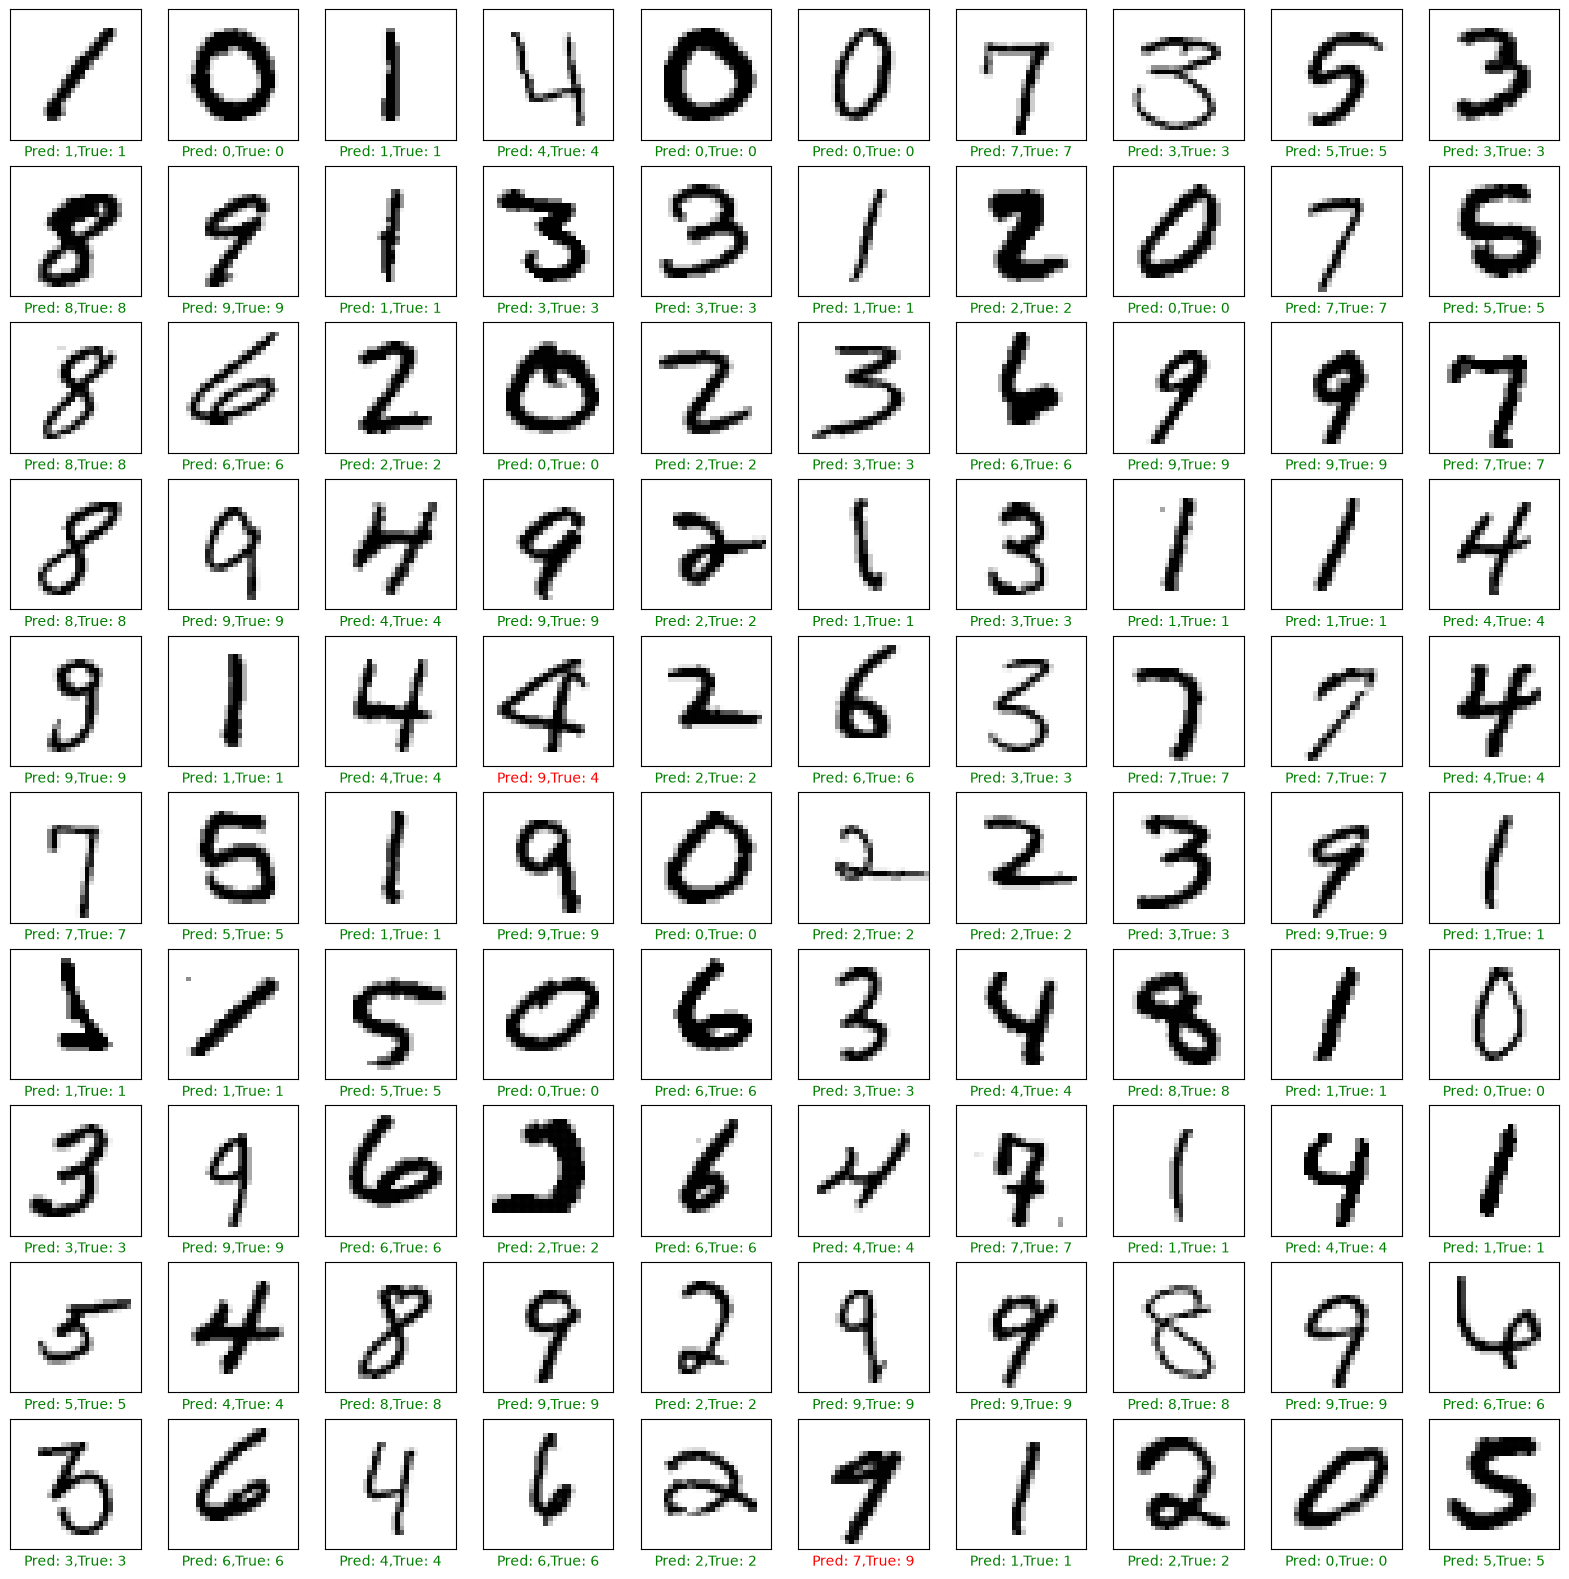

In [26]:
plt.figure(figsize=(20, 20))
for i in range(100):
    plt.subplot(10, 10, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(features[i], cmap=plt.cm.binary)
    predicted_label = np.argmax(predictions[i])
    true_label = labels[i]
    if predicted_label == true_label:
        color = 'green'
    else:
        color = 'red'
    plt.xlabel(f"Pred: {predicted_label},True: {true_label}", color=color)
plt.show()